In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso, Ridge
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV


In [ ]:
# Load the dataset and select only white wine data
dfw = pd.read_csv('datasets/winequality-white.csv', delimiter=';')
dfw.fillna(dfw.mean(), inplace=True)
X = dfw.loc[:, dfw.columns != 'quality']
y = dfw['quality']  # Target
dfw.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [55]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, shuffle=True)

In [56]:
class RidgeRegressionGD:
    def __init__(self, learning_rate=0.00001, n_iterations=1000, alpha=0.1):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.theta = None
    
    def fit(self, X, y):
        m, n = X.shape
        self.theta = np.zeros(n)
        

        for i in range(self.n_iterations):
            predictions = X.dot(self.theta)
            errors = predictions - y
            
            gradient = (1 / m) * (X.T.dot(errors)) + self.alpha * self.theta
            self.theta -= self.learning_rate * gradient
                
    
    def predict(self, X):
        return X.dot(self.theta)


# Train the model
ridge_gd = RidgeRegressionGD(learning_rate=0.000001, n_iterations=1000, alpha=0.1)
ridge_gd.fit(X_train, y_train)

# Predict and evaluate
m_pred = ridge_gd.predict(X_test)
print("Final cost:", mean_squared_error(m_pred, y_test))


Final cost: 4.095414047996956


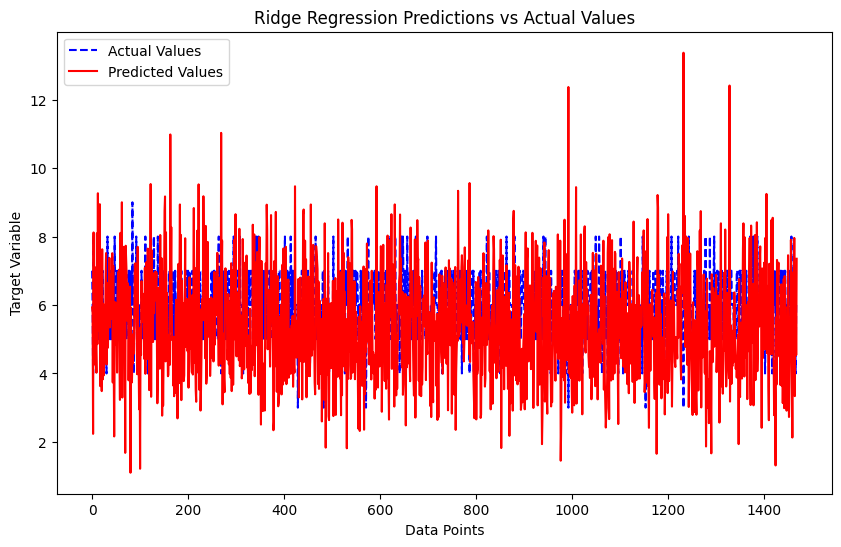

In [57]:
# Plotting the predictions against the actual values
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(y_test)), y_test, label='Actual Values', color='blue', linestyle='dashed')
plt.plot(np.arange(len(m_pred)), m_pred, label='Predicted Values', color='red', linestyle='solid')
plt.xlabel('Data Points')
plt.ylabel('Target Variable')
plt.title('Ridge Regression Predictions vs Actual Values')
plt.legend()
plt.show()

In [58]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# Assuming dfw is already loaded and preprocessed
dfw = pd.read_csv('datasets/winequality-white.csv', delimiter=';')
dfw.fillna(dfw.mean(), inplace=True)
X = dfw.loc[:, dfw.columns != 'quality']
y = dfw['quality']  # Target

# Scaling features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, shuffle=True)

class RidgeRegressionSGD:
    def __init__(self, learning_rate=0.00001, n_iterations=1000, alpha=0.1):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.theta = None
    
    def fit(self, X, y):
        # Ensure X and y are NumPy arrays (they should be after scaling and train-test split)
        X = np.array(X)
        y = np.array(y)
        
        m, n = X.shape
        self.theta = np.zeros(n)
        
        for _ in range(self.n_iterations):
            # Create a random permutation of indices
            for i in np.random.permutation(m):
                xi = X[i]  # xi is the row from X
                yi = y[i]  # yi is the corresponding value from y
                error = np.dot(xi, self.theta) - yi
                gradient = xi * error + self.alpha * self.theta
                self.theta -= self.learning_rate * gradient
    
    def predict(self, X):
        return np.dot(X, self.theta)

# Train the model
ridge_gd = RidgeRegressionSGD(learning_rate=0.000001, n_iterations=1000, alpha=0.1)
ridge_gd.fit(X_train, y_train)

# Predict and evaluate
m_pred = ridge_gd.predict(X_test)
print("Final cost:", mean_squared_error(m_pred, y_test))


Final cost: 0.6183951975648141


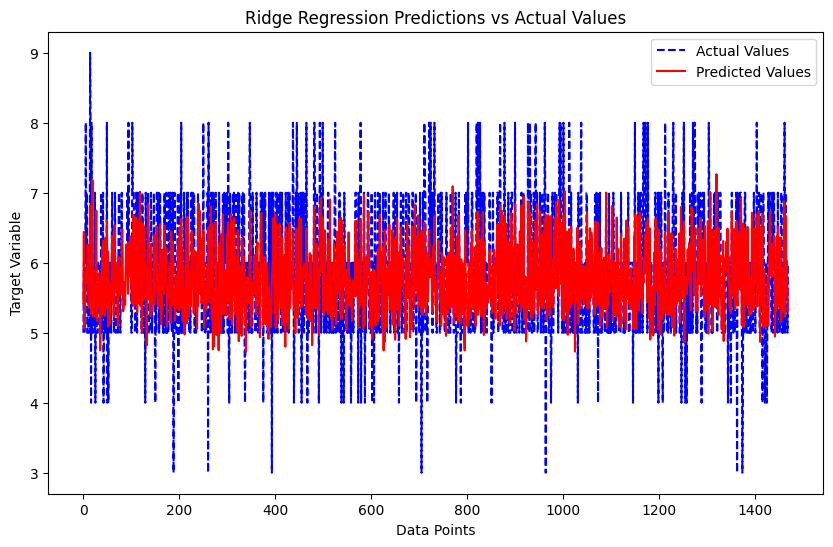

In [59]:
# Plotting the predictions against the actual values
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(y_test)), y_test, label='Actual Values', color='blue', linestyle='dashed')
plt.plot(np.arange(len(m_pred)), m_pred, label='Predicted Values', color='red', linestyle='solid')
plt.xlabel('Data Points')
plt.ylabel('Target Variable')
plt.title('Ridge Regression Predictions vs Actual Values')
plt.legend()
plt.show()

In [49]:
import time
from sklearn.metrics import mean_squared_error

learning_rates = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]

# For Ridge GD
opt_lr_gd = None
opt_mse_gd = None
convergence_time_gd = {}

print("Ridge GD:")
for lr in learning_rates:
    start_time_gd = time.time()
    model = RidgeRegressionGD(learning_rate=lr, alpha=0.1, n_iterations=1000)
    ridge_gd = model.fit(X_train, y_train)
    pred_gd = model.predict(X_test)
    mse_gd = mean_squared_error(y_test, pred_gd)
    convergence_time_gd[lr] = time.time() - start_time_gd
    
    print(f"Learning rate: {lr}; MSE: {mse_gd}; Time: {convergence_time_gd[lr]} seconds")
    
    # Track the optimal learning rate based on MSE
    if opt_lr_gd is None or mse_gd < opt_mse_gd:
        opt_lr_gd = lr
        opt_mse_gd = mse_gd

print(f"Ridge GD: Optimal learning rate: {opt_lr_gd}; MSE: {opt_mse_gd}")
print(f"Convergence time for GD: {convergence_time_gd[opt_lr_gd]} seconds")

# For Ridge SGD
opt_lr_sgd = None
opt_mse_sgd = None
convergence_time_sgd = {}

print("\nRidge SGD:")
for lr in learning_rates:
    start_time_sgd = time.time()
    model = RidgeRegressionSGD(learning_rate=lr, alpha=0.1, n_iterations=1000)
    ridge_sgd = model.fit(X_train, y_train)
    pred_sgd = model.predict(X_test)
    mse_sgd = mean_squared_error(y_test, pred_sgd)
    convergence_time_sgd[lr] = time.time() - start_time_sgd
    
    print(f"Learning rate: {lr}; MSE: {mse_sgd}; Time: {convergence_time_sgd[lr]} seconds")
    
    # Track the optimal learning rate based on MSE
    if opt_lr_sgd is None or mse_sgd < opt_mse_sgd:
        opt_lr_sgd = lr
        opt_mse_sgd = mse_sgd

print(f"Ridge SGD: Optimal learning rate: {opt_lr_sgd}; MSE: {opt_mse_sgd}")
print(f"Convergence time for SGD: {convergence_time_sgd[opt_lr_sgd]} seconds")


Ridge GD:
Learning rate: 1e-09; MSE: 34.15787534468403; Time: 1.5580050945281982 seconds
Learning rate: 1e-08; MSE: 24.275305191616873; Time: 1.1917572021484375 seconds
Learning rate: 1e-07; MSE: 4.731940976558321; Time: 1.111649751663208 seconds
Learning rate: 1e-06; MSE: 4.213300773211181; Time: 1.0862298011779785 seconds
Learning rate: 1e-05; MSE: 3.214763088634151; Time: 1.110502004623413 seconds
Learning rate: 0.0001; MSE: 9.96529429844446e+205; Time: 1.1018073558807373 seconds
Ridge GD: Optimal learning rate: 1e-05; MSE: 3.214763088634151
Convergence time for GD: 1.110502004623413 seconds

Ridge SGD:
Learning rate: 1e-09; MSE: 3.91000279899551; Time: 19.63259768486023 seconds
Learning rate: 1e-08; MSE: 1.7169262375624272; Time: 18.74947762489319 seconds
Learning rate: 1e-07; MSE: 0.6522797532025708; Time: 18.767919778823853 seconds
Learning rate: 1e-06; MSE: 0.6279801105838329; Time: 20.10272240638733 seconds
Learning rate: 1e-05; MSE: 0.6148615303800877; Time: 19.068583965301514

C:\Users\EC\AppData\Local\Temp\ipykernel_16316\756310635.py:40: RuntimeWarning: overflow encountered in multiply
  gradient = xi * error + self.alpha * self.theta
C:\Users\EC\AppData\Local\Temp\ipykernel_16316\756310635.py:41: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.learning_rate * gradient


ValueError: Input contains NaN.